# EDA

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
df = pd.read_csv('customers_clean.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [32]:
print("Shape is: ", df.shape)

Shape is:  (7032, 21)


In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7032 entries, 0 to 7031
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   object 
 1   gender            7032 non-null   object 
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   object 
 4   Dependents        7032 non-null   object 
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   object 
 7   MultipleLines     7032 non-null   object 
 8   InternetService   7032 non-null   object 
 9   OnlineSecurity    7032 non-null   object 
 10  OnlineBackup      7032 non-null   object 
 11  DeviceProtection  7032 non-null   object 
 12  TechSupport       7032 non-null   object 
 13  StreamingTV       7032 non-null   object 
 14  StreamingMovies   7032 non-null   object 
 15  Contract          7032 non-null   object 
 16  PaperlessBilling  7032 non-null   object 


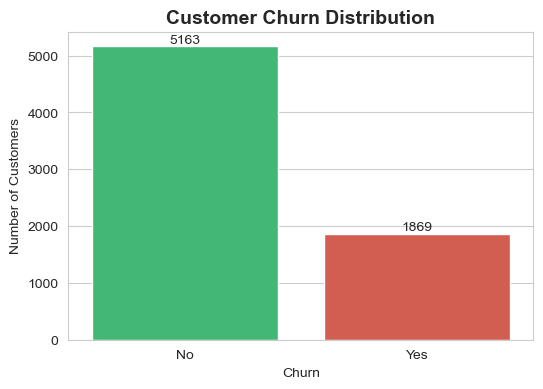

In [34]:
sns.set_style('whitegrid')

plt.figure(figsize=(6,4))
ax = sns.countplot(data=df, x='Churn',hue='Churn', palette=['#2ecc71', '#e74c3c'], legend=False)

plt.title('Customer Churn Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')

for container in ax.containers:
    ax.bar_label(container)

plt.show()

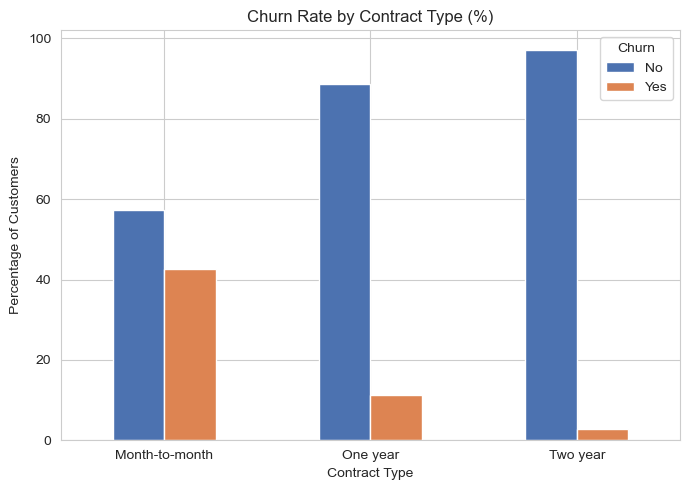

In [35]:
contract_churn = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100

contract_churn.plot(kind='bar', stacked=False, figsize=(7,5), color=['#4C72B0', '#DD8452'])

plt.title('Churn Rate by Contract Type (%)')
plt.xlabel('Contract Type')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=0)
plt.legend(title='Churn')
plt.tight_layout()
plt.show()

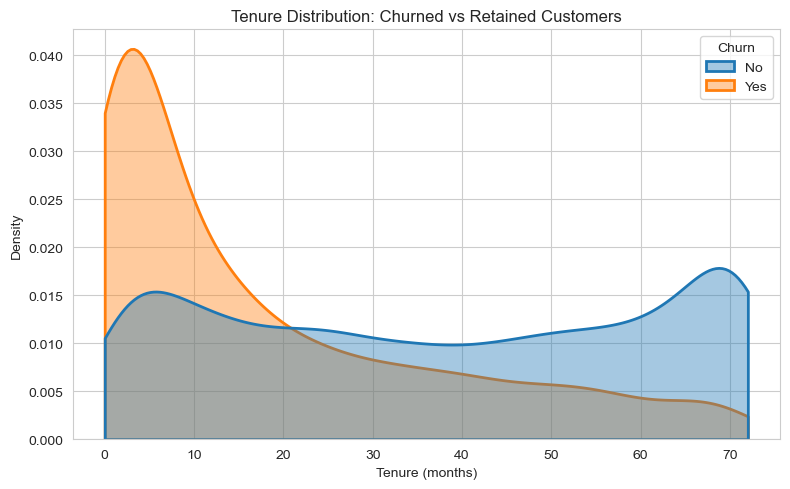

In [36]:
plt.figure(figsize=(8,5))

sns.kdeplot(data=df, x='tenure', hue='Churn', fill=True, 
            common_norm=False, alpha=0.4, linewidth=2,
            clip=(0, df['tenure'].max()))

plt.title('Tenure Distribution: Churned vs Retained Customers')
plt.xlabel('Tenure (months)')
plt.ylabel('Density')
plt.tight_layout()
plt.show()

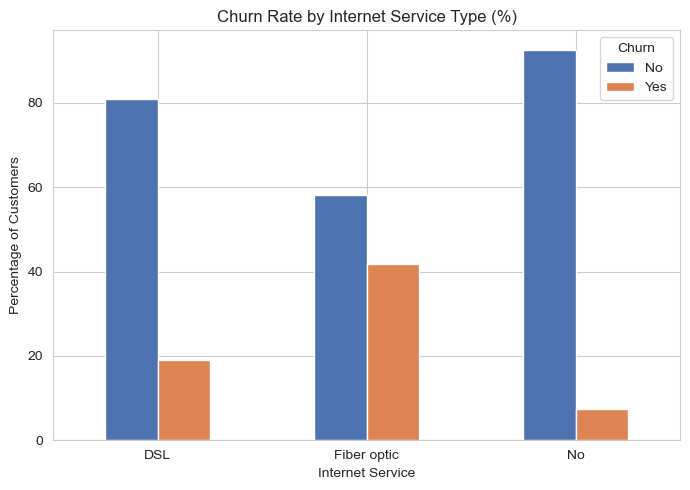

In [37]:
internet_churn = pd.crosstab(df['InternetService'], df['Churn'], normalize='index') * 100

internet_churn.plot(kind='bar', stacked=False, figsize=(7,5), color=['#4C72B0', '#DD8452'])

plt.title('Churn Rate by Internet Service Type (%)')
plt.xlabel('Internet Service')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=0)
plt.legend(title='Churn')
plt.tight_layout()
plt.show()

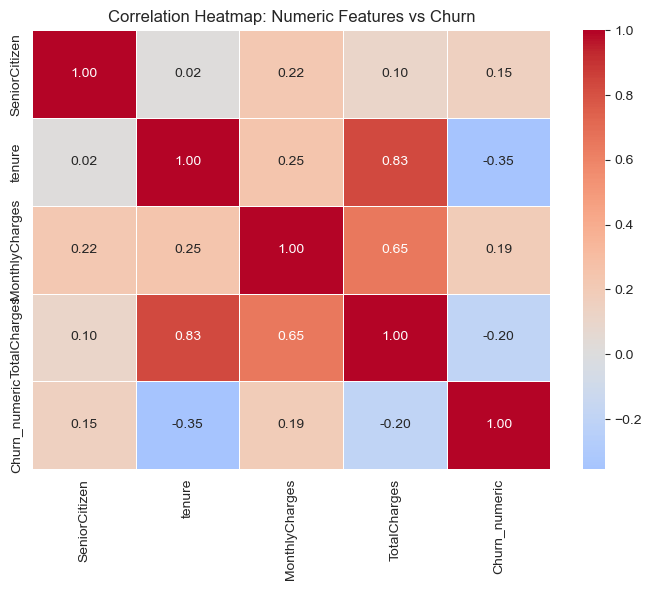

In [38]:
df_corr = df.copy()
df_corr['Churn_numeric'] = df_corr['Churn'].map({'Yes': 1, 'No': 0})

numeric_cols = df_corr.select_dtypes(include=['int64', 'float64']).columns
corr_matrix = df_corr[numeric_cols].corr()

# Plot heatmap
plt.figure(figsize=(7,6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation Heatmap: Numeric Features vs Churn')
plt.tight_layout()
plt.show()

C:\Users\Almagd\AppData\Local\Temp\ipykernel_22932\2892551610.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette=['#4C72B0', '#DD8452'])


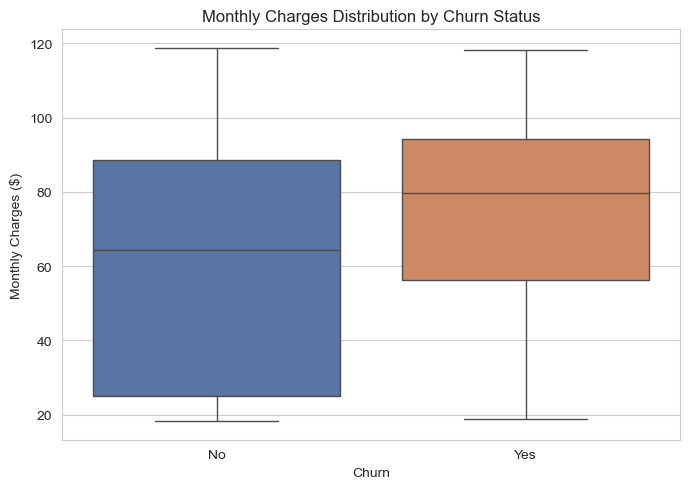

In [39]:
plt.figure(figsize=(7,5))

sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette=['#4C72B0', '#DD8452'])

plt.title('Monthly Charges Distribution by Churn Status')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges ($)')
plt.tight_layout()
plt.show()

# Feature Engineering

In [40]:
# a clean backup before transforming the data
df_backup = df.copy()

In [41]:
pd.set_option("display.max_colwidth", None)

unique_values = df.select_dtypes(include='object').drop(columns='customerID').apply(lambda col: col.unique())
print(unique_values)

gender                                                                                    [Female, Male]
Partner                                                                                        [Yes, No]
Dependents                                                                                     [No, Yes]
PhoneService                                                                                   [No, Yes]
MultipleLines                                                                [No phone service, No, Yes]
InternetService                                                                   [DSL, Fiber optic, No]
OnlineSecurity                                                            [No, Yes, No internet service]
OnlineBackup                                                              [Yes, No, No internet service]
DeviceProtection                                                          [No, Yes, No internet service]
TechSupport                                            

In [42]:
# Columns that contain the redundant "No internet service" value
internet_dependent_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                            'TechSupport', 'StreamingTV', 'StreamingMovies']

for col in internet_dependent_cols:
    df[col] = df[col].replace('No internet service', 'No')

df['MultipleLines'] = df['MultipleLines'].replace('No phone service', 'No')

# Confirm each column now has only 2 unique values
for col in internet_dependent_cols + ['MultipleLines']:
    print(f"{col}: {df[col].unique()}")

OnlineSecurity: ['No' 'Yes']
OnlineBackup: ['Yes' 'No']
DeviceProtection: ['No' 'Yes']
TechSupport: ['No' 'Yes']
StreamingTV: ['No' 'Yes']
StreamingMovies: ['No' 'Yes']
MultipleLines: ['No' 'Yes']


In [43]:
df = df.drop(columns='customerID')

print(df.columns.tolist())

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [44]:
df['estimated_total'] = df['tenure'] * df['MonthlyCharges']
comparison = df[['TotalCharges', 'estimated_total']].head(10)
print(comparison)

df['diff_pct'] = ((df['TotalCharges'] - df['estimated_total']).abs() / df['TotalCharges']) * 100
print(f"\nAverage difference: {df['diff_pct'].mean():.2f}%")

# Clean up temp columns
df = df.drop(columns=['estimated_total', 'diff_pct'])

   TotalCharges  estimated_total
0         29.85            29.85
1       1889.50          1936.30
2        108.15           107.70
3       1840.75          1903.50
4        151.65           141.40
5        820.50           797.20
6       1949.40          1960.20
7        301.90           297.50
8       3046.05          2934.40
9       3487.95          3481.30

Average difference: 3.21%


In [45]:
# Drop TotalCharges — confirmed as ~97% derivable from tenure * MonthlyCharges (3.21% avg diff)
# and highly collinear with tenure (0.83 correlation)
df = df.drop(columns='TotalCharges')

print(df.columns.tolist())
print("Remaining columns: ", {df.shape[1]})

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'Churn']
Remaining columns:  {19}


### Binary Encoder

In [46]:
# Columns with Yes/No values
yes_no_cols = ['Churn', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling',
               'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
               'TechSupport', 'StreamingTV', 'StreamingMovies']

for col in yes_no_cols:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

df['gender'] = df['gender'].map({'Male': 1, 'Female': 0})

print(df.dtypes)
print(df[['Churn', 'gender', 'Partner']].head())

gender                int64
SeniorCitizen         int64
Partner               int64
Dependents            int64
tenure                int64
PhoneService          int64
MultipleLines         int64
InternetService      object
OnlineSecurity        int64
OnlineBackup          int64
DeviceProtection      int64
TechSupport           int64
StreamingTV           int64
StreamingMovies       int64
Contract             object
PaperlessBilling      int64
PaymentMethod        object
MonthlyCharges      float64
Churn                 int64
dtype: object
   Churn  gender  Partner
0      0       0        1
1      0       1        0
2      1       1        0
3      0       1        0
4      1       0        0


In [47]:
# One-Hot Encode the remaining multi-category columns
df = pd.get_dummies(df, columns=['InternetService', 'Contract', 'PaymentMethod'], 
                     drop_first=True)

print(df.dtypes)
print(df.shape)

gender                                     int64
SeniorCitizen                              int64
Partner                                    int64
Dependents                                 int64
tenure                                     int64
PhoneService                               int64
MultipleLines                              int64
OnlineSecurity                             int64
OnlineBackup                               int64
DeviceProtection                           int64
TechSupport                                int64
StreamingTV                                int64
StreamingMovies                            int64
PaperlessBilling                           int64
MonthlyCharges                           float64
Churn                                      int64
InternetService_Fiber optic                 bool
InternetService_No                          bool
Contract_One year                           bool
Contract_Two year                           bool
PaymentMethod_Credit

# Building Machine Learning Models

### Preparing the Data for the Models

In [48]:
X = df.drop(columns='Churn')
y = df['Churn']

print(X.columns.tolist())

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nX columns:")
print(X.columns.tolist())
print("\ny value counts:")
print(y.value_counts())

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'MonthlyCharges', 'InternetService_Fiber optic', 'InternetService_No', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']
X shape: (7032, 22)
y shape: (7032,)

X columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'MonthlyCharges', 'InternetService_Fiber optic', 'InternetService_No', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']

y value counts:
Churn
0    5163
1    1869
Name: count, dtype: int64


In [49]:
# Train Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (5625, 22)
X_test shape: (1407, 22)


In [50]:
# Standard Scaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train[['tenure', 'MonthlyCharges']] = scaler.fit_transform(X_train[['tenure', 'MonthlyCharges']])
X_test[['tenure', 'MonthlyCharges']] = scaler.transform(X_test[['tenure', 'MonthlyCharges']])

### Logistic Regression

In [51]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

lr = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
lr.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [52]:
y_pred_lr = lr.predict(X_test)

In [53]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Confusion Matrix:
[[730 303]
 [ 80 294]]


In [54]:
print("Classification Report:")
print(classification_report(y_test, y_pred_lr))

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.71      0.79      1033
           1       0.49      0.79      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



### Random Forest

In [55]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(class_weight='balanced', random_state=42, n_estimators=100)
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [56]:
y_pred_rf = rf.predict(X_test)

In [57]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Confusion Matrix:
[[923 110]
 [194 180]]


In [58]:
print("Classification Report:")
print(classification_report(y_test, y_pred_rf))

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.62      0.48      0.54       374

    accuracy                           0.78      1407
   macro avg       0.72      0.69      0.70      1407
weighted avg       0.77      0.78      0.77      1407



### XGBoost

In [59]:
from xgboost import XGBClassifier

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=42, 
                            eval_metric='logloss')
xgb_model.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


In [60]:
y_pred_xgb = xgb_model.predict(X_test)

In [61]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

Confusion Matrix:
[[797 236]
 [129 245]]


In [62]:
print("Classification Report:")
print(classification_report(y_test, y_pred_xgb))

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.77      0.81      1033
           1       0.51      0.66      0.57       374

    accuracy                           0.74      1407
   macro avg       0.69      0.71      0.69      1407
weighted avg       0.77      0.74      0.75      1407



### SVM

In [63]:
from sklearn.svm import SVC

svm_model = SVC(class_weight='balanced', random_state=42, probability=True)
svm_model.fit(X_train, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,True
,tol,0.001
,cache_size,200
,class_weight,'balanced'
,verbose,False


In [64]:
y_pred_svm = svm_model.predict(X_test)

In [65]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

Confusion Matrix:
[[728 305]
 [ 83 291]]


In [66]:
print("Classification Report:")
print(classification_report(y_test, y_pred_svm))

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.70      0.79      1033
           1       0.49      0.78      0.60       374

    accuracy                           0.72      1407
   macro avg       0.69      0.74      0.69      1407
weighted avg       0.79      0.72      0.74      1407



# Hyperparameter Tuning

### Random Forest

In [67]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# Define the grid of hyperparameters to try
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': ['balanced', 'balanced_subsample']
}

rf_base = RandomForestClassifier(random_state=42)

grid_search_rf = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search_rf.fit(X_train, y_train)

print("Best parameters:", grid_search_rf.best_params_)
print("Best F1-score (cross-validated):", grid_search_rf.best_score_)

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best parameters: {'class_weight': 'balanced', 'max_depth': 5, 'min_samples_leaf': 4, 'n_estimators': 100}
Best F1-score (cross-validated): 0.6343045333145789


In [68]:
best_rf = grid_search_rf.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_tuned))

Confusion Matrix:
[[728 305]
 [ 81 293]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.70      0.79      1033
           1       0.49      0.78      0.60       374

    accuracy                           0.73      1407
   macro avg       0.69      0.74      0.70      1407
weighted avg       0.79      0.73      0.74      1407



### XGBoost

In [69]:
from xgboost import XGBClassifier

# Define the grid of hyperparameters for XGBoost
param_grid_xgb = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'scale_pos_weight': [1, scale_pos_weight]  # try both unweighted and imbalance-corrected
}

xgb_base = XGBClassifier(random_state=42, eval_metric='logloss')

grid_search_xgb = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid_xgb,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search_xgb.fit(X_train, y_train)

print("Best parameters:", grid_search_xgb.best_params_)
print("Best F1-score (cross-validated):", grid_search_xgb.best_score_)

Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'scale_pos_weight': np.float64(2.762541806020067)}
Best F1-score (cross-validated): 0.6329910876050585


In [70]:
# Get the best XGBoost model found by GridSearch
best_xgb = grid_search_xgb.best_estimator_

y_pred_xgb_tuned = best_xgb.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb_tuned))

Confusion Matrix:
[[727 306]
 [ 76 298]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.70      0.79      1033
           1       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.80      0.73      0.74      1407



# Feature Importance from XGBoost

                                  Feature  Importance
18                      Contract_Two year    0.268438
17                      Contract_One year    0.177611
15            InternetService_Fiber optic    0.132352
16                     InternetService_No    0.121662
20         PaymentMethod_Electronic check    0.043874
4                                  tenure    0.038143
12                        StreamingMovies    0.037889
7                          OnlineSecurity    0.025511
13                       PaperlessBilling    0.018926
11                            StreamingTV    0.017068
5                            PhoneService    0.014137
3                              Dependents    0.013752
1                           SeniorCitizen    0.013132
10                            TechSupport    0.010647
0                                  gender    0.010235
21             PaymentMethod_Mailed check    0.009919
14                         MonthlyCharges    0.009835
2                           

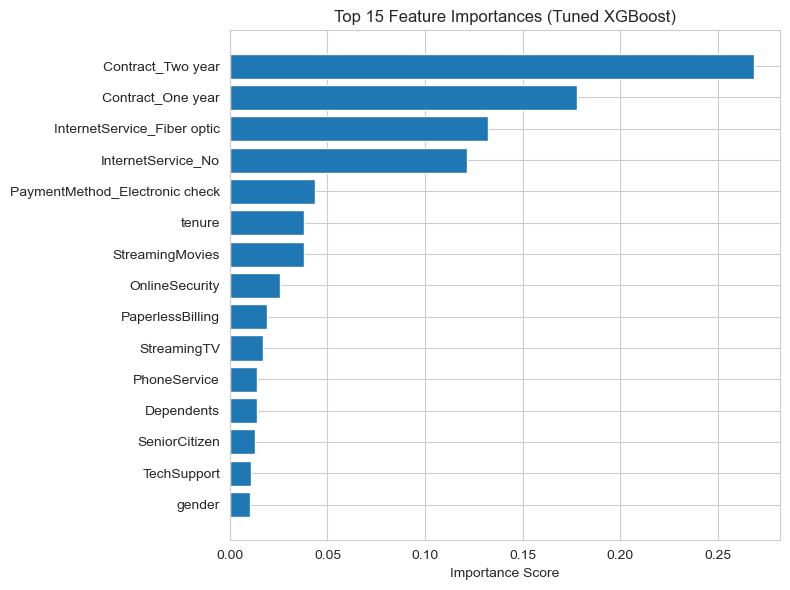

In [71]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importances from the tuned XGBoost model
importances = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': best_xgb.feature_importances_
}).sort_values(by='Importance', ascending=False)

print(importances)

# Plot top 15 features
plt.figure(figsize=(8,6))
plt.barh(importances['Feature'][:15][::-1], importances['Importance'][:15][::-1])
plt.title('Top 15 Feature Importances (Tuned XGBoost)')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

In [72]:
import joblib
joblib.dump(best_xgb, 'xgb_churn_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(X_train.columns.tolist(), 'feature_columns.pkl')

['feature_columns.pkl']

In [73]:
import joblib
import numpy as np

# Load saved artifacts
loaded_model = joblib.load("xgb_churn_model.pkl")
loaded_scaler = joblib.load("scaler.pkl")
loaded_features = joblib.load("feature_columns.pkl")

# 1. Check feature columns
print("Number of saved features:", len(loaded_features))
print("Number of training features:", X_train.shape[1])
print("Features match:", loaded_features == X_train.columns.tolist())

# 2. Check scaler configuration
print("\nScaler feature count:", loaded_scaler.n_features_in_)
print("Scaler feature names:", getattr(loaded_scaler, "feature_names_in_", "Not stored"))

# 3. Check model feature count
print("\nModel feature count:", loaded_model.n_features_in_)

# 4. Check prediction using saved model
sample = X_test.iloc[:5].copy()

sample_scaled = sample.copy()
sample_scaled[["tenure", "MonthlyCharges"]] = loaded_scaler.transform(
    sample[["tenure", "MonthlyCharges"]]
)

predictions = loaded_model.predict(sample_scaled)

print("\nSample predictions:", predictions)
print("Compatibility check completed.")

Number of saved features: 22
Number of training features: 22
Features match: True

Scaler feature count: 2
Scaler feature names: ['tenure' 'MonthlyCharges']

Model feature count: 22

Sample predictions: [0 1 0 0 0]
Compatibility check completed.


In [74]:
import numpy as np

# Use the same test samples
sample = X_test.iloc[:20].copy()

# Apply the saved scaler to the two numerical columns
sample_scaled = sample.copy()

sample_scaled[["tenure", "MonthlyCharges"]] = loaded_scaler.transform(
    sample[["tenure", "MonthlyCharges"]]
)

# Predictions from the loaded model
saved_predictions = loaded_model.predict(sample_scaled)

# Predictions from the original model
original_predictions = best_xgb.predict(sample_scaled)

# Compare predictions
print(
    "Predictions match:",
    np.array_equal(saved_predictions, original_predictions)
)

print("Saved model predictions:", saved_predictions)
print("Original model predictions:", original_predictions)

Predictions match: True
Saved model predictions: [0 1 0 0 0 1 0 0 1 0 1 0 1 0 0 1 1 1 0 0]
Original model predictions: [0 1 0 0 0 1 0 0 1 0 1 0 1 0 0 1 1 1 0 0]
